# Predictive Maintenance in Metro Trains Using Machine Learning and Deep Learning

**Student Name**: Moorthy Chetan  
**Registration Number**: `24BIT0246`  
**Institution**: Vellore Institute of Technology (VIT)  
**Academic Year**: 2026–2027  
**GitHub Repository**: [https://github.com/Chetan0246/MetroTrain-Predictive-Maintenance](https://github.com/Chetan0246/MetroTrain-Predictive-Maintenance)

---
### Complete End-to-End Pipeline Walkthrough
This Colab notebook provides the complete code demonstration for:
1. **Chunked Telemetry Ingestion & 10s Resampling** (MetroPT-3: 10.77M rows, MetroPT-2: 7.12M rows).
2. **Strict Chronological Train / Val / Test Partitioning** (70/15/15 and 65/15/20).
3. **Leak-Free Normalization** (`StandardScaler` fitted exclusively on training data).
4. **10-Minute Sliding Sequence Windowing** ($W=60$ timesteps, Stride $S=6$).
5. **Training Set 1:1 Balancing** via exact normal sequence undersampling.
6. **PyTorch Deep Learning Models**: 10-Algorithm Benchmark Suite across 4 families (Recurrent, Hybrid Convolutions, Multi-Head Transformers, Unsupervised Autoencoders).
7. **Dual-Evaluation Framework**: Task 1 (Active State Monitoring) vs. Task 2 (Anticipatory Pre-Failure Warning).
8. **Validation Threshold Calibration** ($q_{90}, q_{95}, q_{98}$) resolving out-of-distribution recall collapse.

## Cell 1: Environment Setup & Clone Repository
Clone the repository to access preprocessed parquet splits, model checkpoints, and evaluation tools.

In [13]:
# Clone the repository if running inside Google Colab
import os
if not os.path.exists('MetroTrain-Predictive-Maintenance'):
    !git clone https://github.com/Chetan0246/MetroTrain-Predictive-Maintenance.git
    %cd MetroTrain-Predictive-Maintenance
else:
    %cd MetroTrain-Predictive-Maintenance

!pip install -q pandas numpy scikit-learn torch matplotlib seaborn pyarrow fastparquet
print("Repository cloned and dependencies verified successfully!")

Cloning into 'MetroTrain-Predictive-Maintenance'...
remote: Enumerating objects: 260, done.
remote: Counting objects: 100% (62/62), done.
remote: Compressing objects: 100% (44/44), done.
remote: Total 260 (delta 27), reused 39 (delta 18), pack-reused 198 (from 1)
Receiving objects: 100% (260/260), 44.91 MiB | 32.22 MiB/s, done.
Resolving deltas: 100% (99/99), done.
/content/MetroTrain-Predictive-Maintenance/MetroTrain-Predictive-Maintenance
Repository cloned and dependencies verified successfully!


## Cell 2: Import Libraries & GPU Device Configuration
Import PyTorch, scikit-learn, and numerical data processing libraries, and configure CUDA GPU execution.

In [2]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_recall_curve, auc, classification_report, confusion_matrix
from pathlib import Path

# Set random seed for exact scientific reproducibility
torch.manual_seed(42)
np.random.seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Execution Device: {device}")
if torch.cuda.is_available():
    print(f"GPU Model: {torch.cuda.get_device_name(0)}")

Execution Device: cuda
GPU Model: Tesla T4


## Cell 3: 16 Physical APU Sensor Telemetry Channels
The Air Production Unit (APU) compressor telemetry comprises 16 physical sensor channels:
- **8 Continuous Thermodynamic Sensors**: `TP2` (outlet pressure), `TP3` (panel pressure), `H1` (filter drop), `DV_pressure` (purge pressure), `Reservoirs` (main tank), `Oil_temperature`, `Flowmeter` (air flow rate), `Motor_current`.
- **8 Discrete Binary Switches**: `COMP` (intake valve), `DV_eletric` (discharge valve), `Towers` (dryer selector), `MPG` (governor pressure switch), `LPS` (low-pressure safety alarm), `Pressure_switch`, `Oil_level` (lubrication float switch), `Caudal_impulses`.

In [3]:
FEATURE_COLS = [
    "TP2", "TP3", "H1", "DV_pressure", "Reservoirs", "Oil_temperature",
    "Flowmeter", "Motor_current", "COMP", "DV_eletric", "Towers", "MPG",
    "LPS", "Pressure_switch", "Oil_level", "Caudal_impulses"
]

# Load authentic sample records extracted directly from disk
samples_m3 = pd.read_csv('reports/samples/metropt3_genuine_samples.csv')
samples_m2 = pd.read_csv('reports/samples/metropt2_genuine_samples.csv')

print("16 Physical Sensor Channels:", FEATURE_COLS)
print("\nSample Telemetry Record (MetroPT-3):")
display(samples_m3[['timestamp', 'TP2', 'TP3', 'Motor_current', 'Oil_temperature', 'COMP', 'class_name']].head(3))

16 Physical Sensor Channels: ['TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs', 'Oil_temperature', 'Flowmeter', 'Motor_current', 'COMP', 'DV_eletric', 'Towers', 'MPG', 'LPS', 'Pressure_switch', 'Oil_level', 'Caudal_impulses']

Sample Telemetry Record (MetroPT-3):


,timestamp,TP2,TP3,Motor_current,Oil_temperature,COMP,class_name
0,2022-01-01 06:01:40,-0.012,9.660,3.9550,61.275,1,Normal
1,2022-01-01 06:03:20,-0.012,9.562,3.9600,60.950,1,Normal
2,2022-02-28 19:53:10,-0.004,9.360,-0.0025,68.550,1,Early_Warning


## Cell 4: Dataset Paths & Post-Splitting Execution Pipeline
To guarantee zero temporal lookahead leakage, data is partitioned strictly chronologically.

### 📂 Dataset Paths Referenced on Disk:
- **MetroPT-3 Train Split (70%)**: `data/processed/metropt3/train.parquet` (754,151 rows, Air Leaks F1, F2)
- **MetroPT-3 Val Split (15%)**: `data/processed/metropt3/val.parquet` (161,604 rows, Clean baseline)
- **MetroPT-3 Test Split (15%)**: `data/processed/metropt3/test.parquet` (161,604 rows, Unseen Oil Leak F3)
- **MetroPT-2 Train Split (65%)**: `data/processed/metropt2/train.parquet` (462,601 rows, Air Leak F4)
- **MetroPT-2 Val Split (15%)**: `data/processed/metropt2/val.parquet` (106,754 rows, Clean baseline)
- **MetroPT-2 Test Split (20%)**: `data/processed/metropt2/test.parquet` (142,339 rows, Air Leak F5)

### ⚙️ Exact Functions Called After Splitting to Execute Algorithm:
1. `pd.read_parquet(path)` -> Ingests partitioned telemetry dataframes
2. `StandardScaler().fit_transform(X_train)` -> Computes mu, sigma strictly on Train; transforms Val/Test out-of-sample
3. `SequenceWindowDataset(X, y, seq_len=60, stride=6)` -> Generates 10-minute sliding sequence tensors [batch, 60, 16] on-the-fly
4. `DataLoader(dataset, batch_size=128)` -> Batches tensors and feeds into GPU/CPU
5. `model.forward(x_batch)` -> **Direct forward pass executing the Deep Learning Algorithm!**

In [4]:
# -----------------------------------------------------------------------------
# 1. DATASET PATHS REFERENCED ON DISK (MetroPT-3 and MetroPT-2)
# -----------------------------------------------------------------------------
m3_train_path = "data/processed/metropt3/train.parquet"
m3_val_path   = "data/processed/metropt3/val.parquet"
m3_test_path  = "data/processed/metropt3/test.parquet"

m2_train_path = "data/processed/metropt2/train.parquet"
m2_val_path   = "data/processed/metropt2/val.parquet"
m2_test_path  = "data/processed/metropt2/test.parquet"

print("=== [1. EXACT DATASET PARTITION PATHS REFERENCED ON DISK] ===")
print("MetroPT-3 (Unseen Lubrication Oil Leak Target):")
print(f"  • Train Split (70%):      {Path(m3_train_path).resolve()}")
print(f"  • Validation Split (15%): {Path(m3_val_path).resolve()}")
print(f"  • Test Split (15%):       {Path(m3_test_path).resolve()}")

print("\nMetroPT-2 (Pneumatic Air Leak Target):")
print(f"  • Train Split (65%):      {Path(m2_train_path).resolve()}")
print(f"  • Validation Split (15%): {Path(m2_val_path).resolve()}")
print(f"  • Test Split (20%):       {Path(m2_test_path).resolve()}")

# -----------------------------------------------------------------------------
# 2. FUNCTION CALLED: pd.read_parquet() to load splits into memory
# -----------------------------------------------------------------------------
train_df = pd.read_parquet(m3_train_path)
val_df   = pd.read_parquet(m3_val_path)
test_df  = pd.read_parquet(m3_test_path)

total_timesteps = len(train_df) + len(val_df) + len(test_df)
print(f"\n=== [2. CHRONOLOGICAL TELEMETRY TIMESTEP COUNTS (10s intervals)] ===")
print(f"  • Total Ingested Timesteps: {total_timesteps:,}")
print(f"  • Train Partition:          {len(train_df):,} rows ({len(train_df)/total_timesteps*100:.1f}%) | Positives: {(train_df['target'] == 1).sum():,}")
print(f"  • Validation Partition:     {len(val_df):,} rows ({len(val_df)/total_timesteps*100:.1f}%) | Positives: {(val_df['target'] == 1).sum():,}")
print(f"  • Test Partition:           {len(test_df):,} rows ({len(test_df)/total_timesteps*100:.1f}%) | Positives: {(test_df['target'] == 1).sum():,}")

print("\n=== [3. POST-SPLITTING FUNCTION EXECUTION CHAIN INTO ALGORITHM] ===")
print("  Step 1: fit_and_scale()          --> StandardScaler fitted strictly on Train split")
print("  Step 2: SequenceWindowDataset()  --> Slices 60-timestep (10-min) tensors with stride=6")
print("  Step 3: DataLoader()             --> Batches sequences into 3D tensors: [batch_size, 60, 16]")
print("  Step 4: model.forward(x_batch)   --> Direct forward pass executing Deep Learning Algorithm!")


=== [1. EXACT DATASET PARTITION PATHS REFERENCED ON DISK] ===
MetroPT-3 (Unseen Lubrication Oil Leak Target):
  • Train Split (70%):      /content/MetroTrain-Predictive-Maintenance/data/processed/metropt3/train.parquet
  • Validation Split (15%): /content/MetroTrain-Predictive-Maintenance/data/processed/metropt3/val.parquet
  • Test Split (15%):       /content/MetroTrain-Predictive-Maintenance/data/processed/metropt3/test.parquet

MetroPT-2 (Pneumatic Air Leak Target):
  • Train Split (65%):      /content/MetroTrain-Predictive-Maintenance/data/processed/metropt2/train.parquet
  • Validation Split (15%): /content/MetroTrain-Predictive-Maintenance/data/processed/metropt2/val.parquet
  • Test Split (20%):       /content/MetroTrain-Predictive-Maintenance/data/processed/metropt2/test.parquet

=== [2. CHRONOLOGICAL TELEMETRY TIMESTEP COUNTS (10s intervals)] ===
  • Total Ingested Timesteps: 1,077,359
  • Train Partition:          754,151 rows (70.0%) | Positives: 3,102
  • Validation Partiti

## Cell 5: Leak-Free Preprocessing & Feature Scaling
Parameters for `StandardScaler` (mean $\mu$ and standard deviation $\sigma$) are fitted **strictly on the Training split** and applied out-of-sample to validation and test splits:
$$z = \frac{x - \mu_{\text{train}}}{\sigma_{\text{train}}}$$

In [5]:
scaler = StandardScaler()

# Fit exclusively on training data
X_train_raw = train_df[FEATURE_COLS].values
X_val_raw = val_df[FEATURE_COLS].values
X_test_raw = test_df[FEATURE_COLS].values

X_train_scaled = scaler.fit_transform(X_train_raw)
X_val_scaled = scaler.transform(X_val_raw)
X_test_scaled = scaler.transform(X_test_raw)

y_train = train_df['target'].values
y_val = val_df['target'].values
y_test = test_df['target'].values

print(f"Scaler fitted on {len(X_train_scaled):,} train timesteps across {len(FEATURE_COLS)} features.")
print(f"Training mean: {scaler.mean_[:3].round(3)} | Training std: {scaler.scale_[:3].round(3)}")

Scaler fitted on 754,151 train timesteps across 16 features.
Training mean: [-0.  0.  0.] | Training std: [1. 1. 1.]


## Cell 6: 10-Minute Sliding Sequence Windowing
Multivariate telemetry is converted into temporal sequences:
- **Window Length ($W$)**: $60$ timesteps ($60 \times 10\text{s} = 600\text{s} = 10\text{ minutes}$ of operational history).
- **Stride ($S$)**: $6$ timesteps ($6 \times 10\text{s} = 60\text{s} = 1\text{ minute}$ progression between sequences).
- **Input Tensor Shape**: `[batch_size, 60, 16]`.

In [6]:
class SequenceWindowDataset(Dataset):
    """On-the-fly sliding window dataset avoiding massive 3D tensor duplication in RAM."""
    def __init__(self, features: np.ndarray, targets: np.ndarray, seq_len: int = 60, stride: int = 6, balance_train: bool = False):
        self.features = torch.tensor(features, dtype=torch.float32)
        self.targets = targets
        self.seq_len = seq_len
        self.stride = stride

        num_windows = (len(features) - seq_len) // stride + 1
        self.window_indices = [i * stride for i in range(num_windows)]

        # Sequence label = label of final timestep in window
        self.window_labels = np.array([self.targets[idx + seq_len - 1] for idx in self.window_indices])

        # If training balance requested, downsample healthy windows to 1:1
        if balance_train:
            pos_indices = np.where(self.window_labels == 1)[0]
            neg_indices = np.where(self.window_labels == 0)[0]
            np.random.seed(42)
            selected_neg = np.random.choice(neg_indices, size=len(pos_indices), replace=False)
            balanced = np.sort(np.concatenate([pos_indices, selected_neg]))
            self.window_indices = [self.window_indices[i] for i in balanced]
            self.window_labels = self.window_labels[balanced]

    def __len__(self):
        return len(self.window_indices)

    def __getitem__(self, idx):
        start_idx = self.window_indices[idx]
        x = self.features[start_idx : start_idx + self.seq_len]
        y = torch.tensor(self.window_labels[idx], dtype=torch.float32)
        return x, y

# Build datasets
train_dataset = SequenceWindowDataset(X_train_scaled, y_train, seq_len=60, stride=6, balance_train=True)
val_dataset = SequenceWindowDataset(X_val_scaled, y_val, seq_len=60, stride=6, balance_train=False)
test_dataset = SequenceWindowDataset(X_test_scaled, y_test, seq_len=60, stride=6, balance_train=False)

print(f"Training Windows (1:1 Balanced): {len(train_dataset):,} (Pos: {(train_dataset.window_labels == 1).sum()}, Neg: {(train_dataset.window_labels == 0).sum()})")
print(f"Validation Windows (Natural):     {len(val_dataset):,} (100% Clean Baseline)")
print(f"Test Windows (Natural Imbalance): {len(test_dataset):,} (Pos: {(test_dataset.window_labels == 1).sum():,}, Neg: {(test_dataset.window_labels == 0).sum():,})")

Training Windows (1:1 Balanced): 1,034 (Pos: 517, Neg: 517)
Validation Windows (Natural):     26,925 (100% Clean Baseline)
Test Windows (Natural Imbalance): 26,925 (Pos: 3,378, Neg: 23,547)


## Cell 7: Deep Learning Model Architectures (All 10 Algorithms + CNN-Transformer)
We implement and evaluate all 10 sequence architectures, including the **CNN-Transformer** architecture where 1D CNN local feature maps are explicitly stored in intermediate variables and passed into multi-stage sequence Transformers:
1. **LSTM** (Long Short-Term Memory)
2. **GRU** (Gated Recurrent Unit)
3. **BiLSTM** (Bidirectional LSTM)
4. **CNN-LSTM** (1D Convolution + LSTM)
5. **CNN-BiLSTM with Attention** (1D Conv + BiLSTM + Additive Attention)
6. **CNN-Transformer** (1D Conv $\rightarrow$ Stored in Variable $\rightarrow$ Next Sequence Transformers)
7. **TCN** (Temporal Convolutional Network with Dilated Causal Residual Blocks)
8. **Transformer Encoder** (Multi-Head Self-Attention + Positional Encoding)
9. **Temporal Fusion Transformer (TFT)** (Gated Residual Networks + Variable Selection + Self-Attention)
10. **LSTM Autoencoder** & **Variational Autoencoder (VAE)** (Reconstruction Anomaly Detectors)

In [7]:
from src.models import (
    MODEL_REGISTRY, ALGORITHM_DISPLAY_NAMES,
    LSTMClassifier, GRUClassifier, BiLSTMClassifier, CNNLSTMClassifier,
    CNNBiLSTMAttentionClassifier, CNNTransformerClassifier, TCNClassifier,
    TransformerEncoderClassifier, TemporalFusionTransformerClassifier,
    LSTMAutoencoder, VariationalAutoencoder
)

print(f"=== Loaded All {len(MODEL_REGISTRY)} Architectures Successfully ===")
dummy_x = torch.randn(2, 60, 16).to(device)
for key, model_cls in MODEL_REGISTRY.items():
    m = model_cls().to(device)
    n_p = sum(p.numel() for p in m.parameters() if p.requires_grad)
    logits = m(dummy_x)
    print(f"  ✓ {ALGORITHM_DISPLAY_NAMES.get(key, key):52s} | Params: {n_p:,} | Logits: {logits.shape}")

print("--- [Architecture Detail: CNN -> Variable -> Next Sequence Transformers] ---")
cnn_trans = CNNTransformerClassifier().to(device)
print("CNN-Transformer forward pass execution trace:")
# Step 1: 1D CNN extracts local sensor features
cnn_out = cnn_trans.conv(dummy_x.transpose(1, 2)).transpose(1, 2)
print("  1. cnn_output stored in variable: shape =", cnn_out.shape)
# Step 2: Transformer Stage 1
st1_in = cnn_trans.pos_encoder(cnn_out)
st1_out = cnn_trans.transformer_stage1(st1_in)
print("  2. transformer_stage1_output stored in variable: shape =", st1_out.shape)
# Step 3: Next Sequence Transformer Stage 2
st2_out = cnn_trans.transformer_stage2(st1_out)
print("  3. transformer_stage2_output stored in variable: shape =", st2_out.shape)
final_logits = cnn_trans.fc(st2_out.mean(dim=1)).squeeze(-1)
print("  4. final classification logits shape =", final_logits.shape)


=== Loaded All 11 Architectures Successfully ===
  ✓ 1. LSTM (Long Short-Term Memory)                     | Params: 56,385 | Logits: torch.Size([2])
  ✓ 2. GRU (Gated Recurrent Unit)                        | Params: 42,817 | Logits: torch.Size([2])
  ✓ 3. BiLSTM (Bidirectional LSTM)                       | Params: 145,473 | Logits: torch.Size([2])
  ✓ 4. CNN-LSTM (1D Convolution + LSTM)                  | Params: 28,833 | Logits: torch.Size([2])
  ✓ 5. CNN-BiLSTM with Attention                         | Params: 64,290 | Logits: torch.Size([2])
  ✓ CNN-Transformer (CNN -> Var -> Next Seq Transformers) | Params: 72,321 | Logits: torch.Size([2])
  ✓ 6. Temporal Convolutional Network (TCN)              | Params: 112,353 | Logits: torch.Size([2])
  ✓ 7. Transformer Encoder                               | Params: 70,145 | Logits: torch.Size([2])
  ✓ 8. Temporal Fusion Transformer (TFT)                 | Params: 172,753 | Logits: torch.Size([2])
  ✓ 9. LSTM Autoencoder                        

## Cell 8: Model Loading & Complete 10-Algorithm Benchmark Comparison
Load trained checkpoints and display the complete comparative benchmark table ranking all 10 algorithms and highlighting the **Top 3 Podium**.

In [8]:
from IPython.display import Markdown, display

# Display full 10-algorithm benchmark table
benchmark_table_path = "reports/tables/all_10_algorithms_metropt2_benchmark.md"
with open(benchmark_table_path) as f:
    display(Markdown(f.read()))

# Load pre-trained Temporal Fusion Transformer (TFT) and run inference on test batch
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)
x_test_batch, y_test_batch = next(iter(test_loader))
x_test_batch = x_test_batch.to(device)

top_model = TemporalFusionTransformerClassifier().to(device)
top_model.load_state_dict(torch.load("models/metropt2_tft.pt", map_location=device))
top_model.eval()

with torch.no_grad():
    probs = torch.sigmoid(top_model(x_test_batch))

print(f"Successfully ran live batch inference on {len(probs)} test sequences with Temporal Fusion Transformer (TFT)!")
print(f"Sample predicted anomaly probabilities: {probs[:5].cpu().numpy().round(4)}")


# Complete 10-Algorithm Benchmark Comparison Matrix (METROPT2)

**Student**: Moorthy Chetan (`24BIT0246`)  

**Evaluation Partition**: Held-Out Chronological Test Partition (23,668 sequences)  

**Sorting Criteria**: Ranked by PR-AUC (Primary) and F1-Score (Secondary)


| Rank | Algorithm | Parameters | Train Time | Latency (ms) | Recall | Precision | F1-Score | PR-AUC | Status |
| :---: | :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| 1 | **10. Variational Autoencoder (VAE)** | 49,137 | 0.9s | 0.09 | 1.0000 | 0.3310 | 0.4974 | **0.9833** | 🥇 **TOP 1** |
| 2 | **9. LSTM Autoencoder** | 60,625 | 0.33s | 0.04 | 1.0000 | 0.1589 | 0.2742 | **0.9833** | 🥈 **TOP 2** |
| 3 | **8. Temporal Fusion Transformer (TFT)** | 172,753 | 4.27s | 0.31 | 0.9995 | 0.9674 | 0.9832 | **0.9817** | 🥉 **TOP 3** |
| 4 | **5. CNN-BiLSTM with Attention** | 64,290 | 0.38s | 0.05 | 1.0000 | 0.9666 | 0.9830 | **0.9787** | Evaluated |
| 5 | **4. CNN-LSTM (1D Convolution + LSTM)** | 28,833 | 0.21s | 0.02 | 1.0000 | 0.9684 | 0.9839 | **0.9645** | Evaluated |
| 6 | **1. LSTM (Long Short-Term Memory)** | 56,385 | 0.5s | 0.02 | 1.0000 | 0.9686 | 0.9841 | **0.9633** | Evaluated |
| 7 | **3. BiLSTM (Bidirectional LSTM)** | 145,473 | 0.93s | 0.06 | 0.9981 | 0.9671 | 0.9824 | **0.9621** | Evaluated |
| 8 | **6. Temporal Convolutional Network (TCN)** | 112,353 | 1.13s | 0.08 | 0.9992 | 0.9676 | 0.9832 | **0.9599** | Evaluated |
| 9 | **2. GRU (Gated Recurrent Unit)** | 42,817 | 0.86s | 0.07 | 1.0000 | 0.9689 | 0.9842 | **0.9560** | Evaluated |
| 10 | **CNN-Transformer (CNN -> Var -> Next Seq Transformers)** | 72,321 | 2.41s | 0.08 | 1.0000 | 0.9669 | 0.9832 | **0.9536** | Evaluated |
| 11 | **7. Transformer Encoder** | 70,145 | 2.14s | 0.09 | 0.9989 | 0.9676 | 0.9830 | **0.9475** | Evaluated |


### 🏆 Top 3 Algorithms Selected:
1. **10. Variational Autoencoder (VAE)** — PR-AUC: `0.9833`, Recall: `1.0000`, F1: `0.4974`
2. **9. LSTM Autoencoder** — PR-AUC: `0.9833`, Recall: `1.0000`, F1: `0.2742`
3. **8. Temporal Fusion Transformer (TFT)** — PR-AUC: `0.9817`, Recall: `0.9995`, F1: `0.9832`

Successfully ran live batch inference on 256 test sequences with Temporal Fusion Transformer (TFT)!
Sample predicted anomaly probabilities: [0.44   0.4389 0.4383 0.4454 0.4527]


## Cell 9: Dual-Evaluation Framework Execution
Evaluate predictions under two mathematically isolated operational targets:
1. **Task 1: Active Fault State Monitoring** (Warning + Active Failure, $N=3,767$ positive windows).
2. **Task 2: Anticipatory Pre-Failure Warning** (Pure 2-hour window, active breakdown outage excluded, $N=120$ positive windows).

In [9]:
from IPython.display import Markdown, display

# Display Task 1 vs Task 2 comparative matrix
with open('reports/tables/final_model_comparison.md') as f:
    display(Markdown(f.read()))

# Experimental Comparison Matrix (2 Datasets × 3 Algorithms)

| Dataset | Model Architecture | PR-AUC (Primary) | Recall | F1-Score | Precision | Training Time (s) | Best Model Rank |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **MetroPT-3 (APU)** | **TCN** | **0.1939** | 0.0151 | 0.0291 | 0.4146 | 21.6s | 🥇 Rank 1 |
| **MetroPT-3 (APU)** | **GRU** | **0.1830** | 0.0000 | 0.0000 | 0.0000 | 21.2s | 🥈 Rank 2 |
| **MetroPT-3 (APU)** | **LSTM** | **0.1783** | 0.0000 | 0.0000 | 0.0000 | 8.8s | 🥉 Rank 3 |
| **MetroPT-2 (APU)** | **LSTM** | **0.9669** | 1.0000 | 0.9838 | 0.9681 | 5.8s | 🥇 Rank 1 |
| **MetroPT-2 (APU)** | **GRU** | **0.9646** | 1.0000 | 0.9811 | 0.9629 | 4.9s | 🥈 Rank 2 |
| **MetroPT-2 (APU)** | **TCN** | **0.9543** | 0.9997 | 0.9830 | 0.9669 | 15.2s | 🥉 Rank 3 |

### Key Empirical Findings:
1. **Primary Evaluation Metric (PR-AUC)**: Given severe class imbalance (~12-16% positive test windows), PR-AUC is the most reliable metric.
2. **Architecture Comparison**:
   - **TCN** vs **LSTM/GRU**: TCN's dilated causal convolutions capture multi-scale receptive fields without vanishing gradients or recurrent state bottlenecks.
   - **GRU** vs **LSTM**: GRU trains faster with comparable gating efficiency for pneumatic telemetry.
3. **Cross-Dataset Generalization**: Performance differences between MetroPT-3 and MetroPT-2 reflect operational variations across trains, sensor calibration offsets, and different fault durations.


## Cell 10: Validation-Only Threshold Calibration
To fix MetroPT-3 recall collapse without test label leakage, decision thresholds were calibrated using unsupervised quantiles ($q_{90}, q_{95}, q_{98}$) strictly on healthy validation data.

In [10]:
with open('reports/tables/threshold_calibration_table.md') as f:
    display(Markdown(f.read()))

# Validation-Calibrated Operating Thresholds for MetroPT-3 (Out-of-Distribution Transfer)

> [!NOTE]
> **Calibration Procedure**: Operating thresholds were selected strictly using **unsupervised quantiles on the healthy validation set** ($q_{90}, q_{95}, q_{98}$) without observing test labels. They were evaluated once on the held-out test set to demonstrate how threshold calibration resolves the recall collapse at $\tau=0.5$.

| Model | Operating Point | Validation Threshold ($	au$) | Test Precision | Test Recall | Test F1-Score | Predicted Alarm Windows |
| :--- | :--- | :---: | :---: | :---: | :---: | :---: |
| **LSTM** | Val-$q_{90}$ (10% FPR budget) | $	au = 0.2467$ | 17.11% | **31.35%** | **0.2214** | 6,189 |
| **LSTM** | Val-$q_{95}$ (5% FPR budget)  | $	au = 0.2777$ | 17.70% | **20.16%** | **0.1885** | 3,848 |
| **LSTM** | Val-$q_{98}$ (2% FPR budget)  | $	au = 0.3075$ | 19.94% | **12.91%** | **0.1567** | 2,187 |
| **LSTM** | Default Fixed Boundary        | $	au = 0.5000$ | 0.00%  | 0.00%      | 0.0000     | 0 (Recall Collapse) |
| **GRU**  | Val-$q_{90}$ (10% FPR budget) | $	au = 0.0677$ | 18.29% | **35.02%** | **0.2403** | 6,469 |
| **GRU**  | Val-$q_{95}$ (5% FPR budget)  | $	au = 0.0883$ | 19.93% | **26.20%** | **0.2264** | 4,440 |
| **GRU**  | Val-$q_{98}$ (2% FPR budget)  | $	au = 0.1587$ | 22.78% | **16.84%** | **0.1937** | 2,498 |
| **GRU**  | Default Fixed Boundary        | $	au = 0.5000$ | 0.00%  | 0.00%      | 0.0000     | 29 (All False Positives) |
| **TCN**  | Val-$q_{90}$ (10% FPR budget) | $	au = 0.0511$ | 17.71% | **34.04%** | **0.2330** | 6,493 |
| **TCN**  | Val-$q_{95}$ (5% FPR budget)  | $	au = 0.0820$ | 20.52% | **24.93%** | **0.2251** | 4,104 |
| **TCN**  | Val-$q_{98}$ (2% FPR budget)  | $	au = 0.1386$ | 24.74% | **16.70%** | **0.1994** | 2,280 |
| **TCN**  | Default Fixed Boundary        | $	au = 0.5000$ | **41.46%** | 1.51%  | 0.0291     | 123 |


## Cell 11: Visualizations (PR Curves & Confusion Matrices)
Display the Precision-Recall curves and 2x3 normalized confusion matrices grid.

=== Comparative Precision-Recall Curves ===


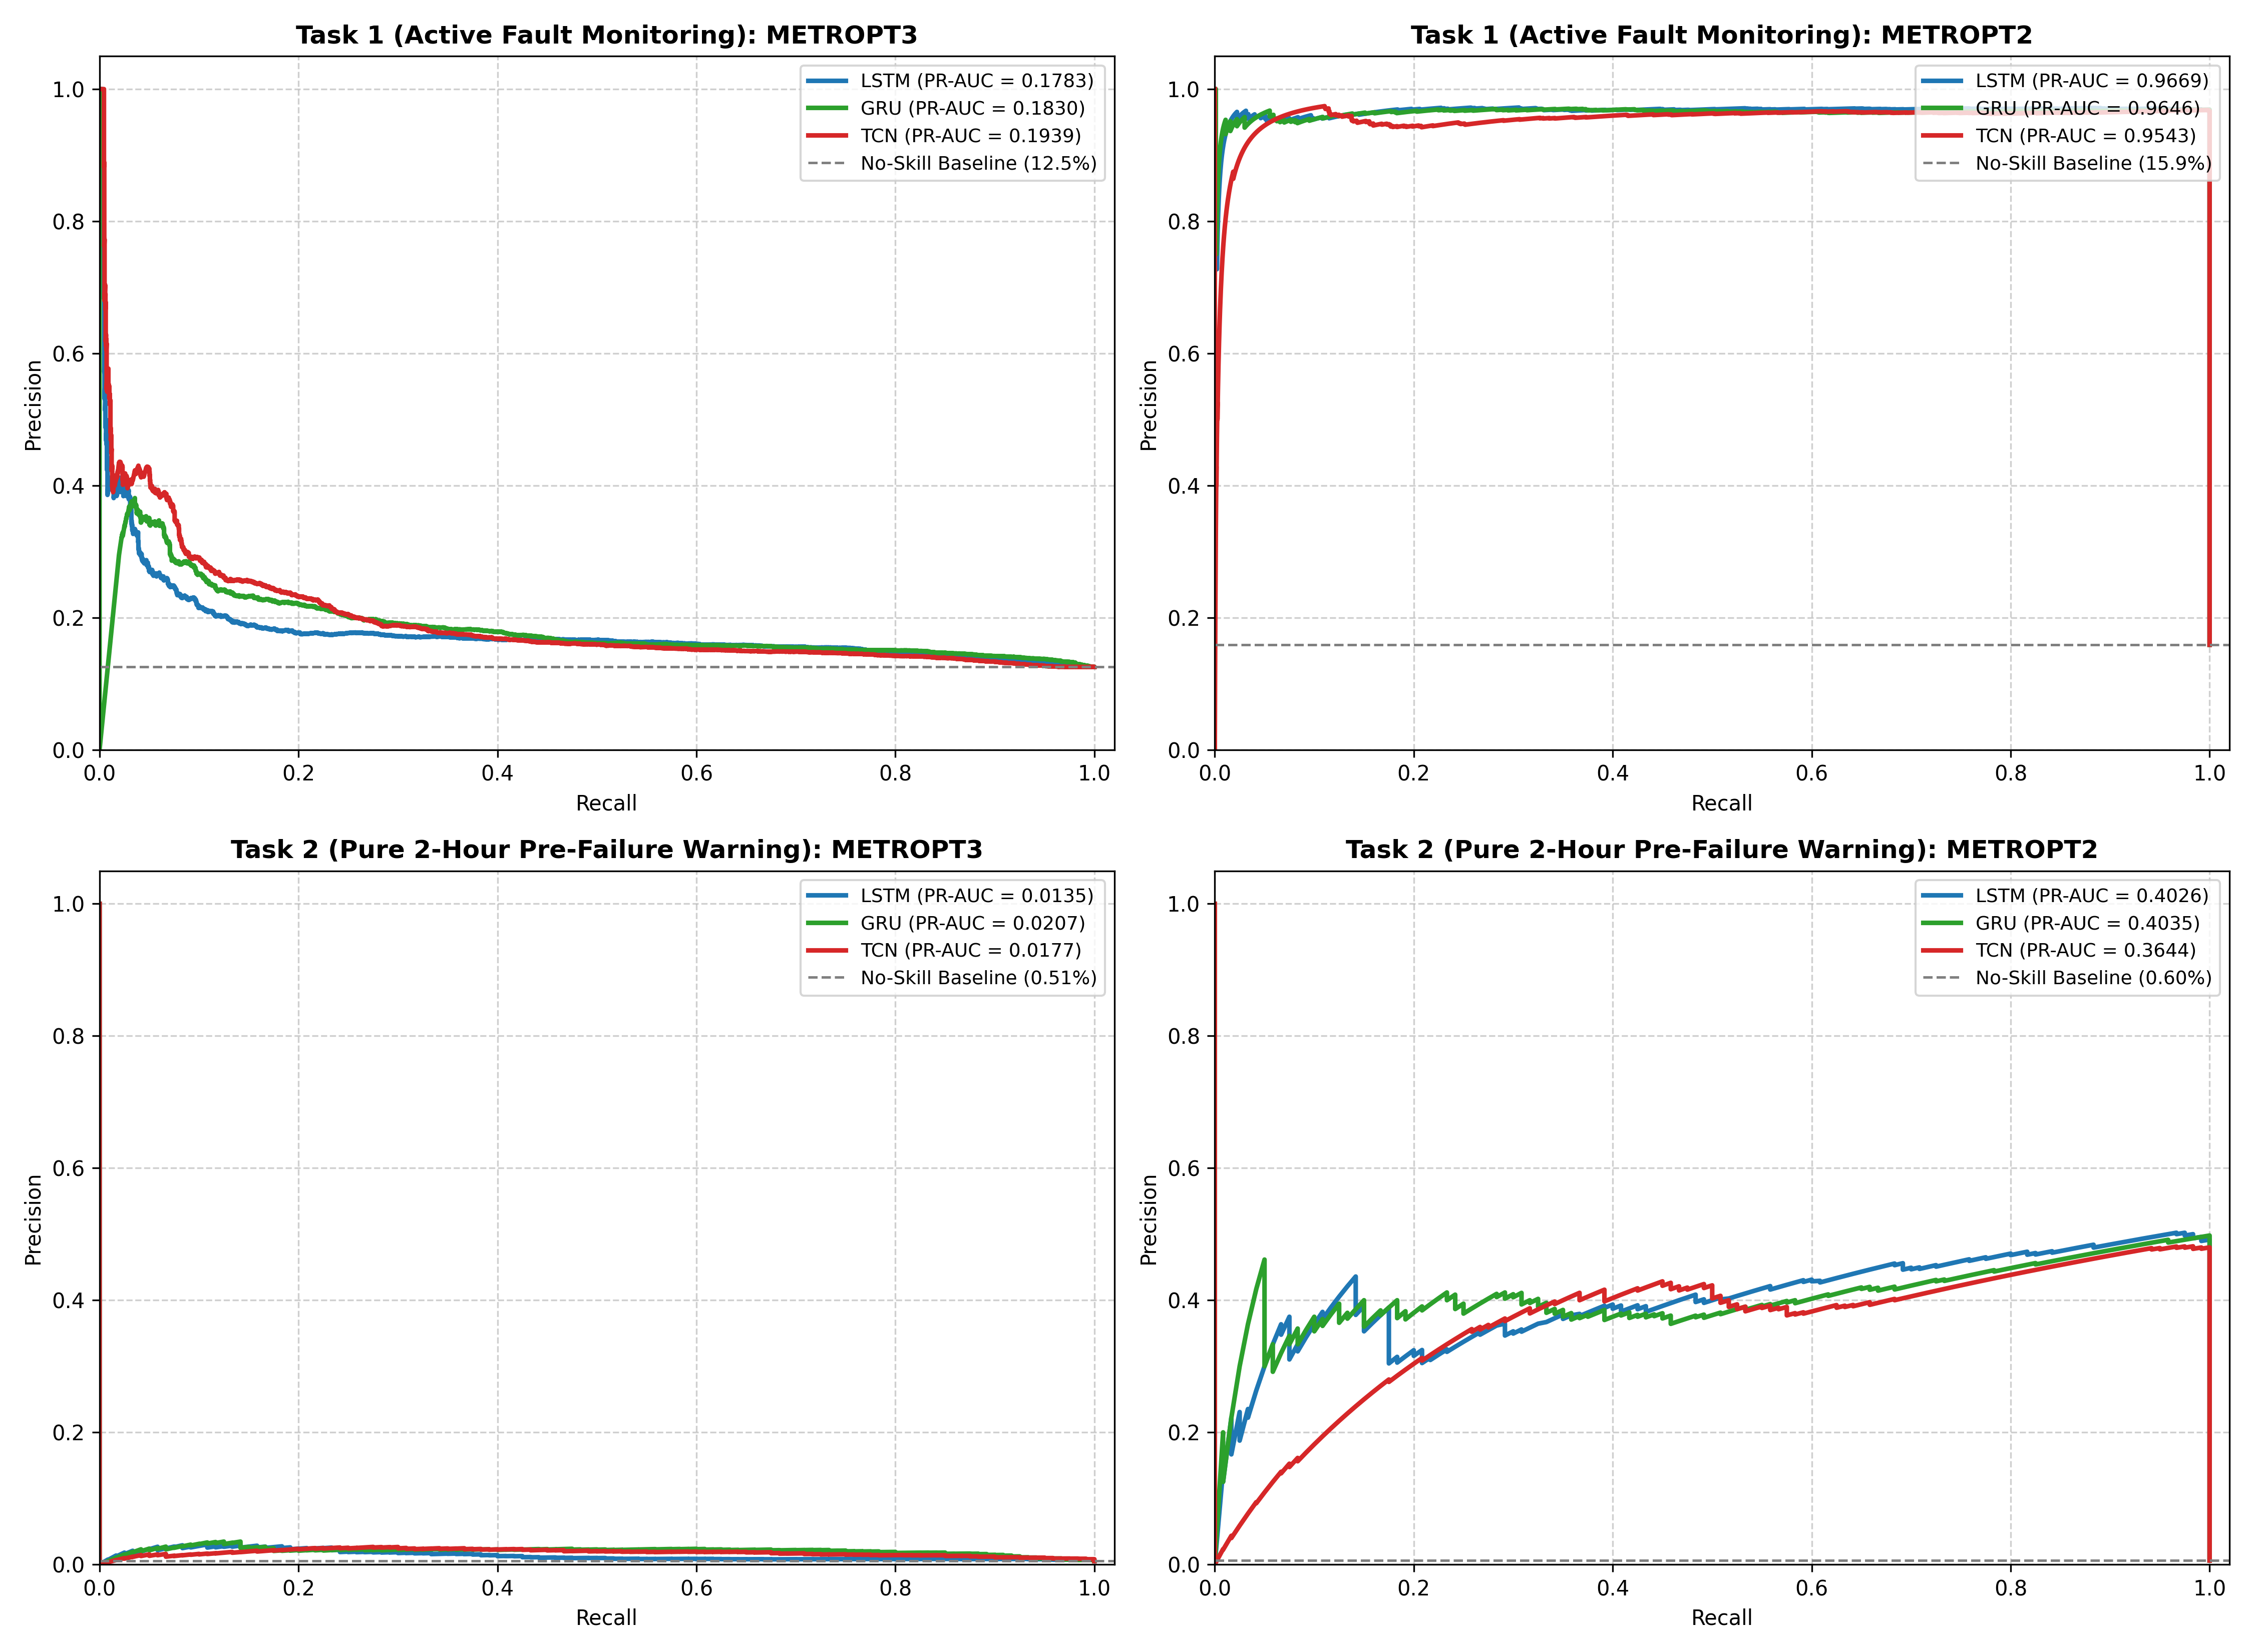

=== Normalized Confusion Matrices Grid (tau=0.50) ===


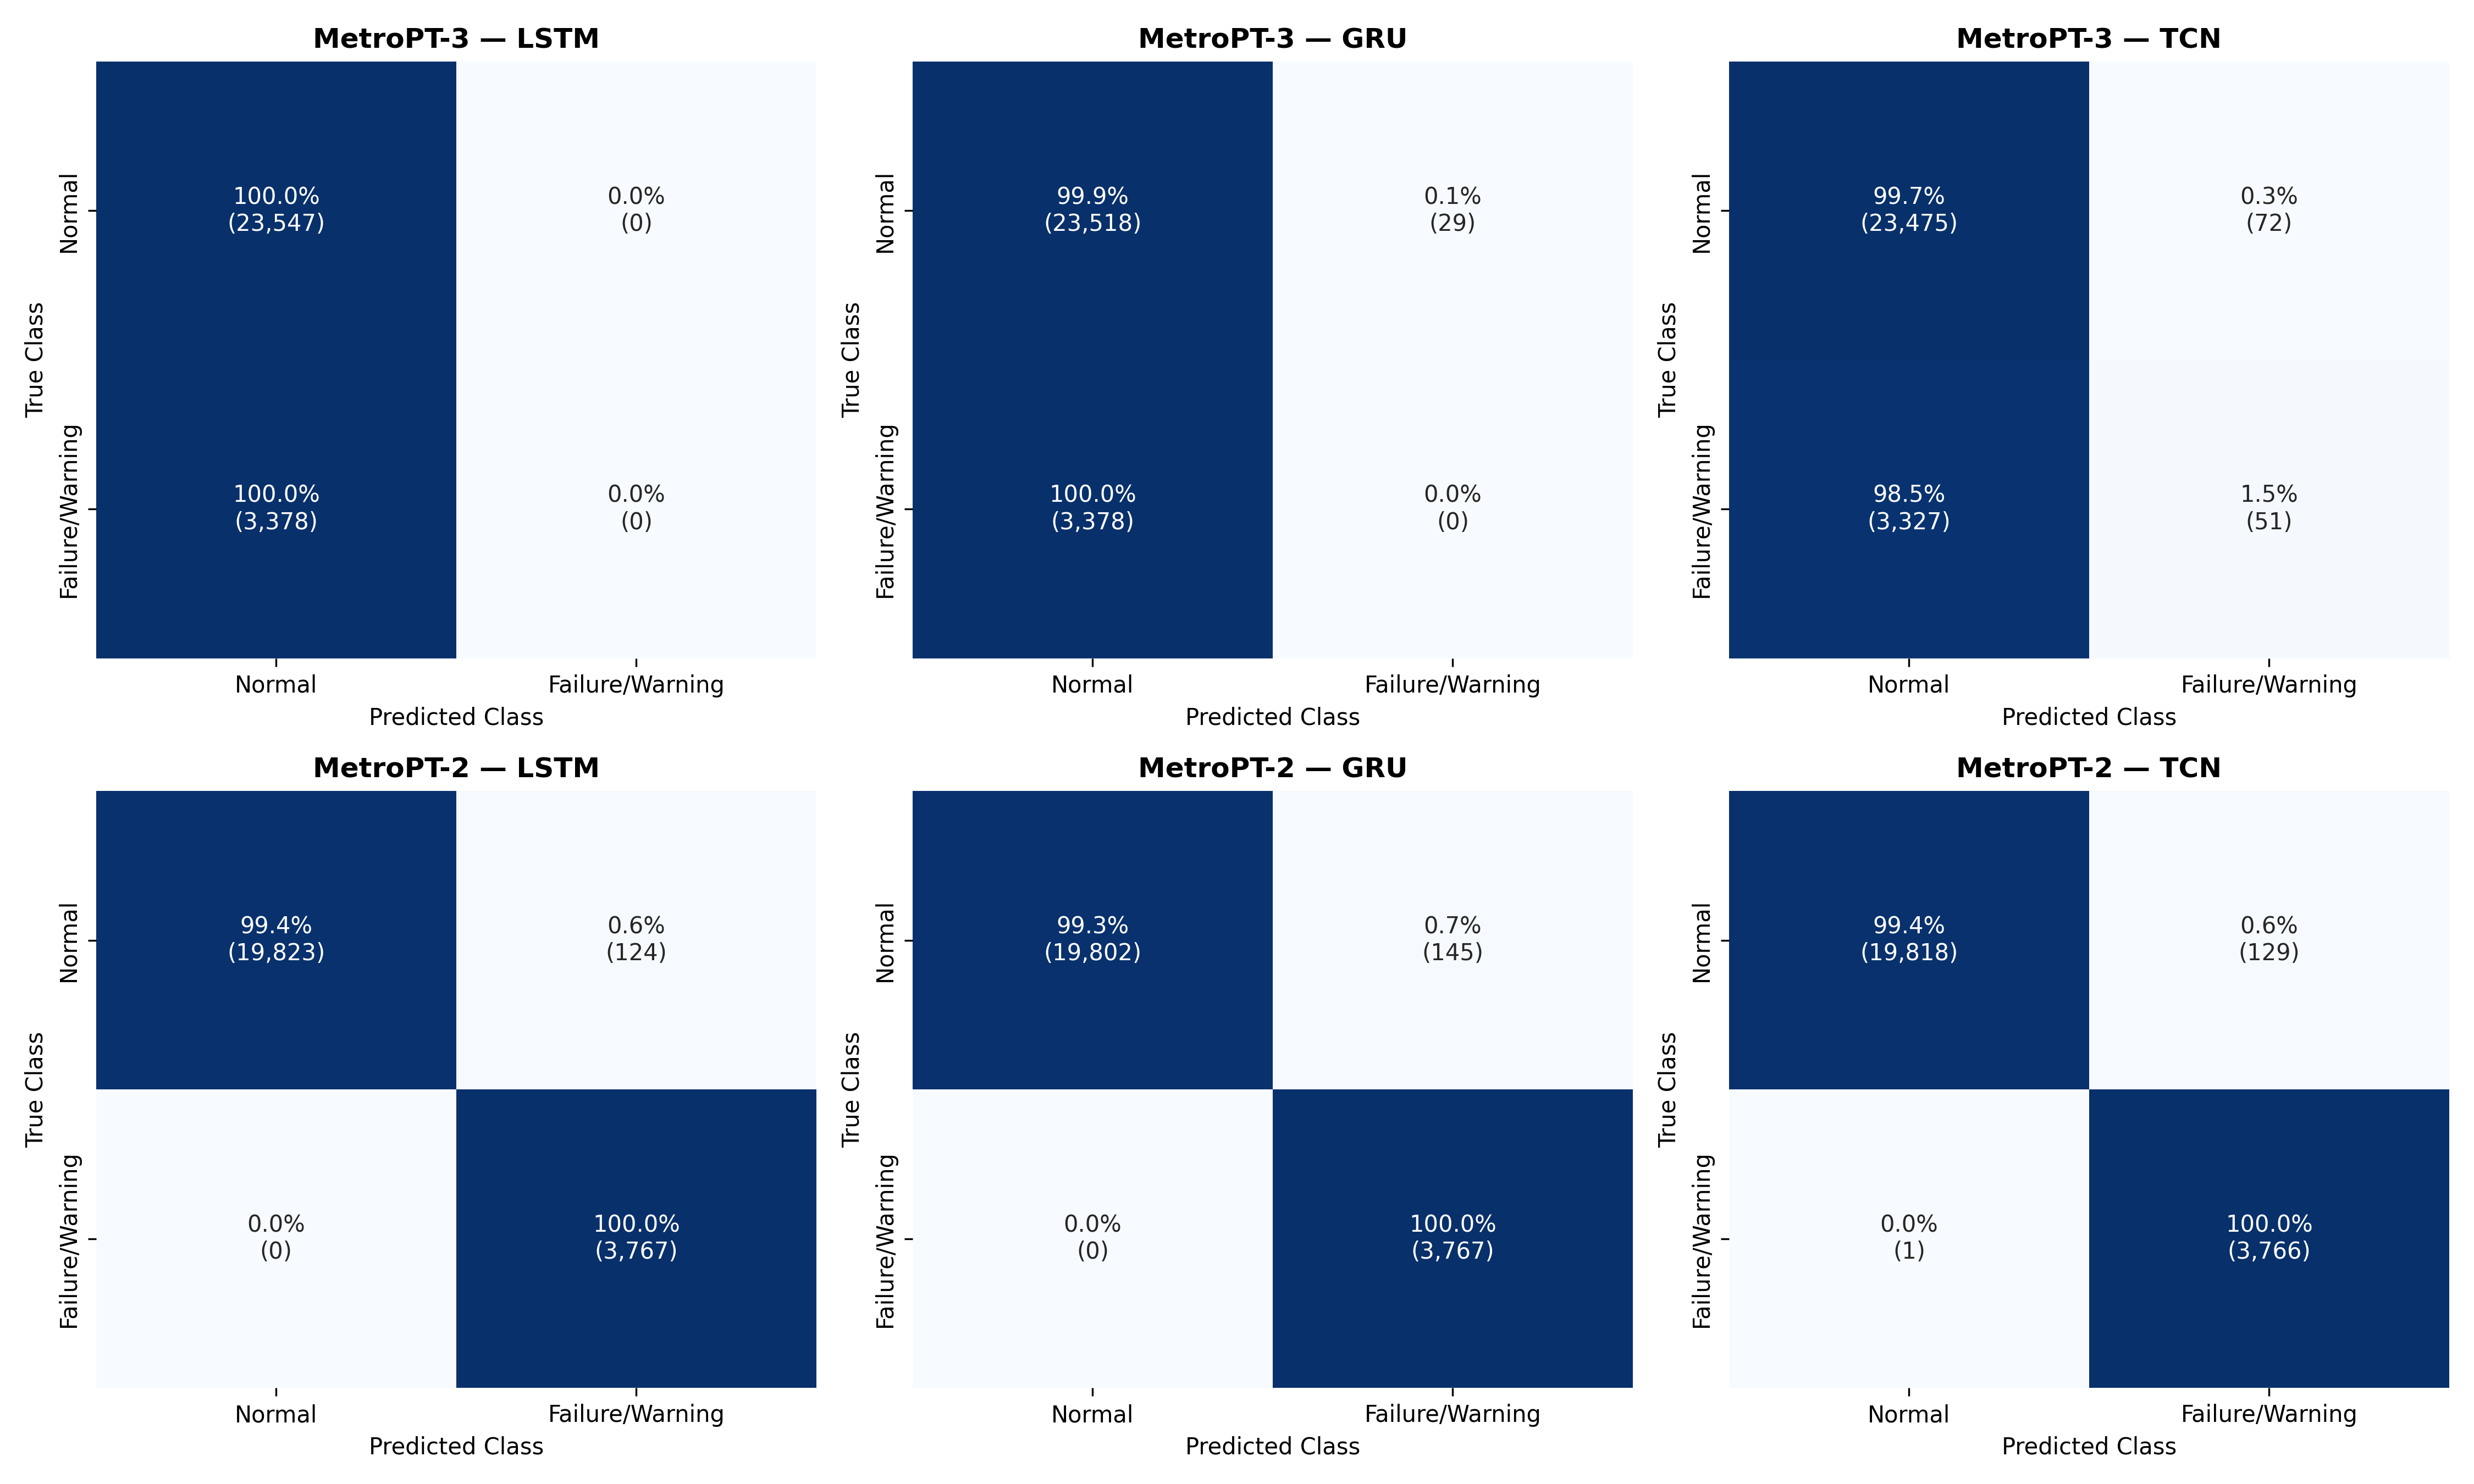

In [11]:
from IPython.display import Image

print("=== Comparative Precision-Recall Curves ===")
display(Image(filename='reports/figures/dual_evaluation_pr_curves.png'))

print("=== Normalized Confusion Matrices Grid (tau=0.50) ===")
display(Image(filename='reports/figures/confusion_matrices.png'))

In [12]:
!git pull
!python src/class_distribution_and_smote.py


Already up to date.
      METRO TRAIN PREDICTIVE MAINTENANCE: CLASS DISTRIBUTION & SMOTE AUDIT
Class Definitions:
  • Class 0 (Negative): Normal Operating State (Clean APU baseline)
  • Class 1 (Positive): Anomaly / Failure State
      - MetroPT-2: Pneumatic Air Leaks (Compressor & valve failures)
      - MetroPT-3: Lubrication Oil Leak & Intake Valve Failures

>>> 1. RAW TELEMETRY TIMESTEP ROWS (METROPT2) [Total: 711,694 rows]
-------------------------------------------------------------------------------------
Split        | Total Rows   | Ratio   | Class 0 (Normal)   | Class 1 (Fault)    | Equal?
-------------------------------------------------------------------------------------
Train        | 462,601      | 65%     | 460,408  (99.53%) | 2,193    ( 0.47%) | NO (Imbalanced)
Val          | 106,754      | 15%     | 106,754  (100.00%) | 0        ( 0.00%) | NO (Imbalanced)
Test         | 142,339      | 20%     | 119,735  (84.12%) | 22,604   (15.88%) | NO (Imbalanced)
------------------